## Implement dropout and batch normalization from scratch by manually modifying weight updates during training, ensuring proper variance stabilization and regularization without built-in layers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Dense:
    def __init__(self, n_in, n_out, rng, std=None):
        std = np.sqrt(2.0 / n_in) if std is None else std         
        self.W, self.b = rng.normal(0, std, (n_in, n_out)), np.zeros(n_out)
    def forward(self, x, train=True):
        self.x = x; return x @ self.W + self.b
    def backward(self, dout):
        self.dW, self.db = self.x.T @ dout, dout.sum(0)
        return dout @ self.W.T
    def params(self): return [(self, 'W', 'dW'), (self, 'b', 'db')]

class ReLU:
    def forward(self, x, train=True):
        self.m = x > 0; return x * self.m
    def backward(self, dout): return dout * self.m
    def params(self): return []

class Dropout:
    def __init__(self, p, rng): self.p, self.rng = p, rng
    def forward(self, x, train=True):
        if not train or self.p == 0: return x                     
        self.mask = (self.rng.random(x.shape) >= self.p) / (1 - self.p)  
        return x * self.mask
    def backward(self, dout): return dout if self.p == 0 else dout * self.mask
    def params(self): return []

class BatchNorm:
    def __init__(self, n, momentum=0.9, eps=1e-5):
        self.gamma, self.beta = np.ones(n), np.zeros(n)
        self.rm, self.rv = np.zeros(n), np.ones(n)                 
        self.mom, self.eps = momentum, eps
    def forward(self, x, train=True):
        if train:
            mu, var = x.mean(0), x.var(0)
            self.rm = self.mom * self.rm + (1 - self.mom) * mu     
            self.rv = self.mom * self.rv + (1 - self.mom) * var
        else:
            mu, var = self.rm, self.rv
        self.inv = 1.0 / np.sqrt(var + self.eps)
        self.xhat = (x - mu) * self.inv
        return self.gamma * self.xhat + self.beta
    def backward(self, dout):
        N = dout.shape[0]
        self.dgamma, self.dbeta = (dout * self.xhat).sum(0), dout.sum(0)
        dxhat = dout * self.gamma
        return self.inv / N * (N * dxhat - dxhat.sum(0) - self.xhat * (dxhat * self.xhat).sum(0))
    def params(self): return [(self, 'gamma', 'dgamma'), (self, 'beta', 'dbeta')]

In [3]:
def softmax_ce(logits, y):
    z = logits - logits.max(1, keepdims=True)
    p = np.exp(z) / np.exp(z).sum(1, keepdims=True)
    loss = -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
    d = p.copy(); d[np.arange(len(y)), y] -= 1
    return loss, d / len(y)                                       

def forward(layers, x, train=True):
    for l in layers: x = l.forward(x, train)
    return x

def backward(layers, d):
    for l in reversed(layers): d = l.backward(d)

def sgd_step(layers, vel, lr=0.05, mom=0.9):
    for li, l in enumerate(layers):
        for obj, pn, gn in l.params():
            key = (li, pn)
            vel[key] = mom * vel.get(key, 0) - lr * getattr(obj, gn)
            setattr(obj, pn, getattr(obj, pn) + vel[key])

In [4]:
rng = np.random.default_rng(0)
drop = Dropout(0.3, rng)
net = [Dense(4, 6, rng), BatchNorm(6), ReLU(), drop, Dense(6, 3, rng)]
x, y = rng.normal(size=(8, 4)), rng.integers(0, 3, 8)

def loss_fn():
    drop.rng = np.random.default_rng(123)                         
    return softmax_ce(forward(net, x), y)[0]

drop.rng = np.random.default_rng(123)                              
l0, d = softmax_ce(forward(net, x), y); backward(net, d)

def num_grad(arr, idx, h=1e-5):
    old = arr[idx]; arr[idx] = old + h; a = loss_fn(); arr[idx] = old - h; b = loss_fn(); arr[idx] = old
    return (a - b) / (2 * h)

for name, arr, grad in [('Dense1.W', net[0].W, net[0].dW), ('BN.gamma', net[1].gamma, net[1].dgamma),
                        ('BN.beta', net[1].beta, net[1].dbeta), ('Dense2.W', net[4].W, net[4].dW)]:
    worst = 0
    for idx in np.ndindex(*arr.shape):
        n = num_grad(arr, idx); a = grad[idx]
        worst = max(worst, abs(n - a) / max(1e-8, abs(n) + abs(a)))
    print(f'{name:9s} max relative error = {worst:.2e}')

Dense1.W  max relative error = 5.70e-09
BN.gamma  max relative error = 1.51e-10
BN.beta   max relative error = 2.15e-10
Dense2.W  max relative error = 2.78e-10


In [5]:
def layer_stds(init_std, use_bn, depth=8, width=100):
    r = np.random.default_rng(1); a = r.normal(size=(512, width)); stds = []
    for _ in range(depth):
        z = a @ r.normal(0, init_std, (width, width))               
        if use_bn: z = (z - z.mean(0)) / np.sqrt(z.var(0) + 1e-5)   
        stds.append(z.std()); a = np.maximum(z, 0)
    return stds

print(f"{'init std':>9s} {'BN':>4s}  pre-activation std per layer (1 -> 8)")
for s in [0.05, 0.14, 0.4]:                                        
    for bn in [False, True]:
        print(f"{s:9.2f} {'yes' if bn else 'no':>4s}  " + ' '.join(f'{v:9.2e}' if v < 0.01 or v > 100 else f'{v:9.3f}' for v in layer_stds(s, bn)))

 init std   BN  pre-activation std per layer (1 -> 8)
     0.05   no      0.492     0.172     0.064     0.020  7.05e-03  2.68e-03  9.76e-04  3.89e-04
     0.05  yes      1.000     1.000     1.000     1.000     1.000     1.000     1.000     1.000
     0.14   no      1.377     1.351     1.405     1.258     1.213     1.294     1.317     1.468
     0.14  yes      1.000     1.000     1.000     1.000     1.000     1.000     1.000     1.000
     0.40   no      3.934    11.032    32.762    83.817  2.31e+02  7.04e+02  2.05e+03  6.52e+03
     0.40  yes      1.000     1.000     1.000     1.000     1.000     1.000     1.000     1.000


In [6]:
r = np.random.default_rng(2)
d = Dropout(0.5, r); x = r.normal(1.0, 1.0, (200000, 1))
out = d.forward(x, train=True)
print(f'Train: mean in={x.mean():.3f} out={out.mean():.3f} | var in={x.var():.3f} out={out.var():.3f}')
print('Test : output == input ?', np.array_equal(d.forward(x, train=False), x))

Train: mean in=0.998 out=0.998 | var in=1.002 out=3.003
Test : output == input ? True


In [7]:
def make_data(n, rng, d=20):
    X = rng.normal(size=(n, d))
    w = np.array([1.5, -2.0, 1.0, 1.0])
    logit = X[:, :4] @ w + 1.5 * X[:, 0] * X[:, 1]                
    y = (logit + rng.normal(0, 1.0, n) > 0).astype(int)             
    return X, y

drng = np.random.default_rng(10)
Xtr, ytr = make_data(200, drng); Xte, yte = make_data(3000, drng)
mu, sd = Xtr.mean(0), Xtr.std(0); Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
print(Xtr.shape, Xte.shape, 'positive share:', ytr.mean().round(2))

(200, 20) (3000, 20) positive share: 0.5


In [11]:
def build(use_bn, p, seed, hidden=(256, 256)):
    r = np.random.default_rng(seed); layers, n = [], Xtr.shape[1]
    for h in hidden:
        layers.append(Dense(n, h, r))
        if use_bn: layers.append(BatchNorm(h))
        layers += [ReLU(), Dropout(p, r)]; n = h
    return layers + [Dense(n, 2, r)]

def evaluate(layers, X, y):
    logits = forward(layers, X, train=False)                       
    return softmax_ce(logits, y)[0], np.mean(logits.argmax(1) == y)

def train(use_bn, p, seed, epochs=100, bs=32, lr=0.02):
    layers, vel, r = build(use_bn, p, seed), {}, np.random.default_rng(seed + 100)
    hist = []
    for ep in range(epochs):
        perm = r.permutation(len(Xtr))
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue                                 
            _, d = softmax_ce(forward(layers, Xtr[b], True), ytr[b])
            backward(layers, d); sgd_step(layers, vel, lr)
        hist.append((*evaluate(layers, Xtr, ytr), *evaluate(layers, Xte, yte)))
    return np.array(hist)                                           

configs = {'Plain': (False, 0.0), 'Dropout (p=0.5)': (False, 0.5),
           'BatchNorm': (True, 0.0), 'BatchNorm + Dropout': (True, 0.5)}
seeds = range(5)
H = {name: [train(bn, p, s) for s in seeds] for name, (bn, p) in configs.items()}

In [12]:
print(f"{'Config':20s} {'Train acc':>13s} {'Test acc':>13s} {'Gap':>7s} {'Test loss':>13s}")
for name, runs in H.items():
    f = np.array([r[-1] for r in runs])
    gap = f[:, 1] - f[:, 3]
    print(f"{name:20s} {f[:,1].mean():.3f}+-{f[:,1].std():.3f} {f[:,3].mean():.3f}+-{f[:,3].std():.3f} "
          f"{gap.mean():7.3f} {f[:,2].mean():.3f}+-{f[:,2].std():.3f}")

Config                   Train acc      Test acc     Gap     Test loss
Plain                1.000+-0.000 0.816+-0.006   0.184 0.885+-0.009
Dropout (p=0.5)      1.000+-0.000 0.814+-0.008   0.186 0.798+-0.074
BatchNorm            0.999+-0.002 0.781+-0.009   0.218 1.111+-0.078
BatchNorm + Dropout  1.000+-0.000 0.818+-0.007   0.182 0.673+-0.026


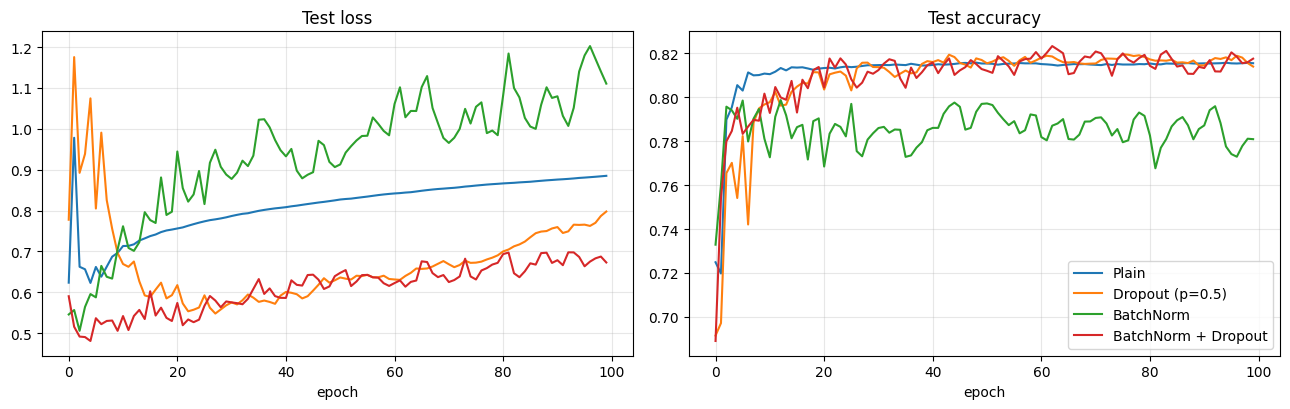

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, runs in H.items():
    m = np.mean(runs, 0)
    ax[0].plot(m[:, 2], label=name); ax[1].plot(m[:, 3], label=name)
ax[0].set_title('Test loss'); ax[1].set_title('Test accuracy')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=0.3)
ax[1].legend(); plt.tight_layout(); plt.show()